# 13. Comparación estadística de los modelos

Con 140 modelos hay 9.730 pares posibles. Probar todos los pares con α = 0,05 daría unos 487 falsos
positivos solo por azar. Por eso la comparación es jerárquica:

- **Clasificación:** Friedman (¿algún modelo difiere?) → Nemenyi y diagrama de Diferencia Crítica →
  DeLong solo entre los finalistas, con corrección de Holm → tamaño del efecto (delta de Cliff).
- **Regresión:** Model Confidence Set sobre las 28 combinaciones → Giacomini-White o Clark-West
  entre los finalistas → Diebold-Mariano (HLN) entre el primero y el segundo, con bootstrap
  estacionario → tamaño del efecto (d de Cohen). Como control de *data snooping*, SPA de Hansen.
- Intervalos de confianza bootstrap (BCa cuando la métrica es una razón de sumas; percentiles para
  AUC) remuestreando **establecimientos completos**.

In [1]:
import sys, json, warnings
sys.path.insert(0, '../src')
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from sklearn.metrics import roc_auc_score, balanced_accuracy_score
from osha_e3 import config as C, models as M, nested as N, final as F, evaluation as E, stats_tests as T, plots as P, cache
P.setup()
fc, fr = N.fold_table('clf'), N.fold_table('reg')
mc, mr = N.master_table('clf'), N.master_table('reg')
test_c, yt_c = F.test_data('clf'); test_r, yt_r = F.test_data('reg')
MODELS_C, MODELS_R = P.MODEL_ORDER_CLF, P.MODEL_ORDER_REG

## 13.1 Clasificación, etapa 1: prueba ómnibus de Friedman

**(a) Las 112 combinaciones** sobre los 5 pliegues externos (bloques), con la balanced accuracy
externa. **(b) Los 7 modelos** (mejor combinación de cada uno según la validación anidada) sobre
14 bloques semanales de la prueba (de lunes a domingo; la primera y la última semana están
incompletas): con solo 5 bloques Nemenyi tiene muy poca potencia, y las
semanas de octubre a diciembre son bloques naturales (independientes del ajuste y ordenados en
el tiempo). **(c) Los 4 optimizadores y las 4 técnicas de balanceo**, con bloques = (modelo ×
balanceo × pliegue) y (modelo × optimizador × pliegue).

In [2]:
pv112 = fc.pivot_table(index='fold', columns=['model', 'balance', 'optimizer'], values='outer_recall')
fr112 = T.friedman(pv112.to_numpy())
best_c = mc.loc[mc.groupby('model').outer_recall_mean.idxmax()].set_index('model').reindex(MODELS_C)
probs = {m: F.load('clf', best_c.loc[m, 'combo'])[0] for m in MODELS_C}
week = pd.to_datetime(test_c.date).dt.to_period('W').astype(str).to_numpy()
weeks = sorted(set(week))
W = pd.DataFrame({M.PRETTY[m]: [balanced_accuracy_score(yt_c[week == w], probs[m][week == w].argmax(1)) for w in weeks] for m in MODELS_C}, index=weeks)
fr7 = T.friedman(W.to_numpy())
pv_opt = fc.pivot_table(index=['model', 'balance', 'fold'], columns='optimizer', values='outer_recall')[M.OPTIMIZERS]
pv_bal = fc.pivot_table(index=['model', 'optimizer', 'fold'], columns='balance', values='outer_recall')[M.BALANCES]
fr_opt, fr_bal = T.friedman(pv_opt.to_numpy()), T.friedman(pv_bal.to_numpy())
pd.DataFrame([
    {'Comparación': '112 combinaciones (bloques: 5 pliegues externos)', 'χ²_F': fr112['chi2'], 'g.l.': fr112['df'], 'p-valor': fr112['p_value'], 'N bloques': fr112['n_blocks']},
    {'Comparación': '7 modelos (bloques: 14 semanas de la prueba)', 'χ²_F': fr7['chi2'], 'g.l.': fr7['df'], 'p-valor': fr7['p_value'], 'N bloques': fr7['n_blocks']},
    {'Comparación': '4 optimizadores (bloques: modelo × balanceo × pliegue)', 'χ²_F': fr_opt['chi2'], 'g.l.': fr_opt['df'], 'p-valor': fr_opt['p_value'], 'N bloques': fr_opt['n_blocks']},
    {'Comparación': '4 balanceos (bloques: modelo × optimizador × pliegue)', 'χ²_F': fr_bal['chi2'], 'g.l.': fr_bal['df'], 'p-valor': fr_bal['p_value'], 'N bloques': fr_bal['n_blocks']},
]).set_index('Comparación').round(5)

,χ²_F,g.l.,p-valor,N bloques
Comparación,,,,
112 combinaciones (bloques: 5 pliegues externos),175.15131,111,0.00010,5
7 modelos (bloques: 14 semanas de la prueba),19.50000,6,0.00340,14
4 optimizadores (bloques: modelo × balanceo × pliegue),9.90984,3,0.01935,140
4 balanceos (bloques: modelo × optimizador × pliegue),7.31143,3,0.06261,140


**Interpretación.** - **112 combinaciones sobre los 5 pliegues:** Friedman rechaza la igualdad (χ² = 175,2 con 111 g.l.,
  p = 0,0001): al menos una combinación difiere de las demás.
- **7 modelos sobre las semanas de la prueba:** también rechaza (χ² = 19,5 con 6 g.l., p = 0,003).
- **Optimizadores:** rechaza con α = 0,05 (χ² = 9,9, p = 0,019), aunque el efecto es pequeño (sección 13.4).
- **Balanceos:** no rechaza (χ² = 7,3, p = 0,063): con balanced accuracy no hay evidencia de que alguna
  técnica de balanceo sea mejor que las otras de forma sistemática. Con AUC macro sí hay diferencias
  (Friedman p = 2·10⁻⁹; `class_weight` es la peor en AUC, rango 3,04, y SMOTE la mejor, 2,04), lo que
  repite que el balanceo cambia el umbral más que la capacidad de ordenar.

Como las pruebas globales rechazan, se pasa al análisis post-hoc.

## 13.2 Clasificación, etapa 2: Nemenyi y diagramas de Diferencia Crítica

Rango promedio: 1 = mejor. Dos modelos unidos por una barra horizontal no difieren
significativamente según Nemenyi (α = 0,05).

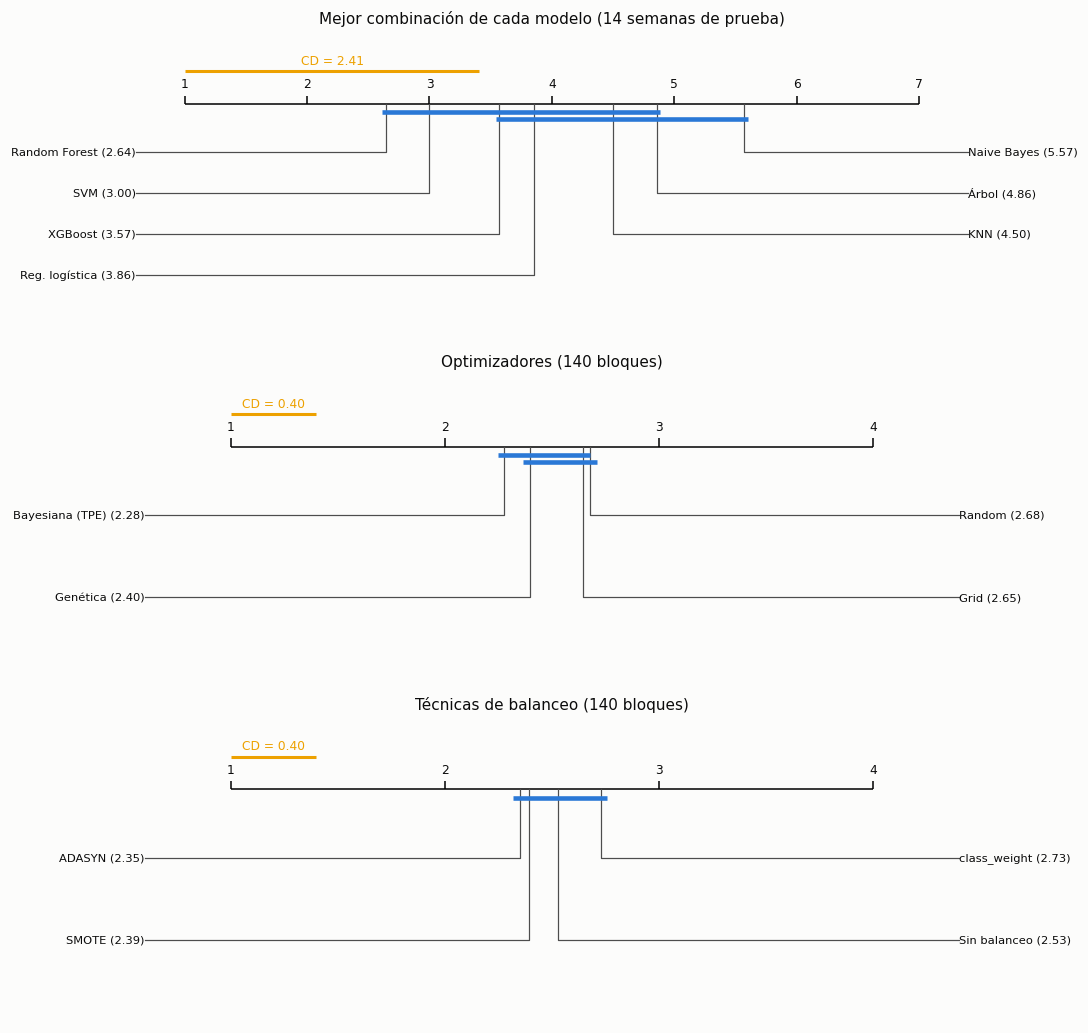

112 combinaciones: CD = 89.4 rangos (sobre 112). Mejor rango promedio 26.2; combinaciones cuyo rango no difiere del mejor: 112 de 112.
Rangos promedio, 7 modelos: {'KNN': 4.5, 'Naive Bayes': 5.57, 'Reg. logística': 3.86, 'Árbol': 4.86, 'Random Forest': 2.64, 'XGBoost': 3.57, 'SVM': 3.0} | CD = 2.41


In [3]:
fig, axes = plt.subplots(3, 1, figsize=(10, 9.5))
cd7 = T.nemenyi_cd(fr7['k'], fr7['n_blocks'])
T.cd_diagram(list(W.columns), fr7['avg_ranks'], cd7, axes[0], f'Mejor combinación de cada modelo ({fr7["n_blocks"]} semanas de prueba)')
cdo = T.nemenyi_cd(fr_opt['k'], fr_opt['n_blocks'])
T.cd_diagram([M.PRETTY[o] for o in M.OPTIMIZERS], fr_opt['avg_ranks'], cdo, axes[1], f'Optimizadores ({fr_opt["n_blocks"]} bloques)')
cdb = T.nemenyi_cd(fr_bal['k'], fr_bal['n_blocks'])
T.cd_diagram([M.PRETTY[b] for b in M.BALANCES], fr_bal['avg_ranks'], cdb, axes[2], f'Técnicas de balanceo ({fr_bal["n_blocks"]} bloques)')
fig.tight_layout(); P.save(fig, 'e3_stats_cd'); plt.show()
cd112 = T.nemenyi_cd(fr112['k'], fr112['n_blocks'])
r112 = pd.Series(fr112['avg_ranks'], index=pv112.columns).sort_values()
print(f'112 combinaciones: CD = {cd112:.1f} rangos (sobre 112). Mejor rango promedio {r112.iloc[0]:.1f}; '
      f'combinaciones cuyo rango no difiere del mejor: {(r112 - r112.iloc[0] < cd112).sum()} de 112.')
print('Rangos promedio, 7 modelos:', dict(zip(W.columns, np.round(fr7['avg_ranks'], 2))), '| CD =', round(cd7, 2))

**Interpretación.** - **112 combinaciones:** con solo 5 bloques, la diferencia crítica de Nemenyi es de 89 rangos sobre 112:
  **ninguna** combinación se distingue estadísticamente de la mejor. Friedman detecta que hay
  diferencias en conjunto, pero 5 pliegues no alcanzan para decir cuáles. Es la limitación que ya anunció
  el capítulo 12 y la razón para comparar las mejores de cada familia sobre bloques más numerosos.
- **7 modelos (14 semanas de prueba):** rangos Random Forest 2,64, SVM 3,00, XGBoost 3,57, logística
  3,86, KNN 4,50, árbol 4,86 y Naive Bayes 5,57, con CD = 2,41. Solo Random Forest difiere
  significativamente de Naive Bayes; los demás pares quedan unidos por las barras (estadísticamente
  equivalentes). Random Forest y SVM encabezan, pero no se separan de XGBoost ni de la logística.
- **Optimizadores:** el bayesiano tiene el mejor rango (2,28) y solo se separa de Random (2,68; diferencia
  0,40, justo en el límite de la CD de 0,40); genético y Grid quedan unidos con todos.
- **Balanceos:** una sola barra une las cuatro técnicas: son equivalentes.

## 13.3 Clasificación: DeLong entre los finalistas, con Holm

Se comparan los tres mejores modelos según el rango de Friedman en la prueba (3 pares). DeLong
compara AUC binarias, así que se aplica a cada clase una contra el resto (4 clases × 3 pares = 12
pruebas) y se ajustan los 12 p-valores con Holm-Bonferroni (y Benjamini-Hochberg como
referencia). El intervalo de la diferencia de AUC es un bootstrap de establecimientos (200 réplicas).

In [4]:
rank7 = pd.Series(fr7['avg_ranks'], index=MODELS_C).sort_values()
final3 = list(rank7.index[:3])
groups = test_c.establishment_id.to_numpy()
codes, uniq = pd.factorize(groups)
def run_delong():
    rows = []
    rng = np.random.default_rng(C.seed_for('bootstrap', 1))
    boots = [np.bincount(rng.integers(0, len(uniq), len(uniq)), minlength=len(uniq))[codes] for _ in range(200)]
    for i in range(3):
        for j in range(i + 1, 3):
            a, b = final3[i], final3[j]
            for k in range(4):
                yk = (yt_c == k)
                d = T.delong_test(yk, probs[a][:, k], probs[b][:, k])
                diffs = [roc_auc_score(yk, probs[a][:, k], sample_weight=w) - roc_auc_score(yk, probs[b][:, k], sample_weight=w) for w in boots]
                lo, hi = np.percentile(diffs, [2.5, 97.5])
                rows.append({'Modelo A': M.PRETTY[a], 'Modelo B': M.PRETTY[b], 'Clase': C.CLASS_NAMES[k], 'AUC A': d['auc1'], 'AUC B': d['auc2'],
                             'Diferencia de AUC': d['diff'], 'IC 95 % bootstrap': f'[{lo:.4f}, {hi:.4f}]', 'z': d['z'], 'p crudo': d['p_value']})
    out = pd.DataFrame(rows)
    out['p Holm'] = T.adjust(out['p crudo'].to_numpy(), 'holm'); out['p BH'] = T.adjust(out['p crudo'].to_numpy(), 'fdr_bh')
    return out
dl = cache.cached('stats_delong', run_delong)
dl.round(4)

,Modelo A,Modelo B,Clase,AUC A,AUC B,Diferencia de AUC,IC 95 % bootstrap,z,p crudo,p Holm,p BH
0,Random Forest,SVM,Fallecimiento,0.6695,0.7203,-0.0508,"[-0.1035, 0.0024]",-1.6990,0.0893,0.2680,0.1072
1,Random Forest,SVM,Días de ausencia,0.6828,0.6374,0.0454,"[0.0405, 0.0506]",34.6540,0.0000,0.0000,0.0000
2,Random Forest,SVM,Traslado/restricción,0.7103,0.6752,0.0350,"[0.0308, 0.0383]",35.6850,0.0000,0.0000,0.0000
3,Random Forest,SVM,Otro registrable,0.7233,0.6797,0.0436,"[0.0377, 0.0478]",39.7508,0.0000,0.0000,0.0000
4,Random Forest,XGBoost,Fallecimiento,0.6695,0.6223,0.0472,"[-0.0471, 0.1243]",1.0307,0.3027,0.4130,0.3027
5,Random Forest,XGBoost,Días de ausencia,0.6828,0.6888,-0.0060,"[-0.0086, -0.0033]",-7.4136,0.0000,0.0000,0.0000
6,Random Forest,XGBoost,Traslado/restricción,0.7103,0.7094,0.0008,"[-0.0018, 0.0031]",1.2632,0.2065,0.4130,0.2253
7,Random Forest,XGBoost,Otro registrable,0.7233,0.7307,-0.0074,"[-0.0097, -0.0053]",-12.8579,0.0000,0.0000,0.0000
8,SVM,XGBoost,Fallecimiento,0.7203,0.6223,0.0981,"[0.0127, 0.1747]",2.4288,0.0151,0.0606,0.0202
9,SVM,XGBoost,Días de ausencia,0.6374,0.6888,-0.0514,"[-0.0567, -0.0464]",-38.2282,0.0000,0.0000,0.0000


**Interpretación.** Se compararon los tres modelos con mejor rango en la prueba (Random Forest, SVM y XGBoost) en las 4
clases (12 pruebas, Holm). Con 127.391 casos, DeLong detecta diferencias muy pequeñas:

- **Random Forest supera a SVM** en las tres clases frecuentes (AUC +0,035 a +0,045; IC bootstrap lejos
  de 0; Holm p < 0,001).
- **XGBoost supera a SVM** en las tres clases frecuentes (+0,034 a +0,051, Holm p < 0,001).
- **Random Forest frente a XGBoost:** XGBoost es mejor en «días de ausencia» y en «otro registrable»
  (+0,006 y +0,007, Holm p < 0,001) y empatan en «traslado/restricción» (p = 0,41). Son diferencias
  significativas pero prácticamente irrelevantes (menos de una centésima de AUC).
- **Fallecimiento:** ninguna diferencia es significativa tras Holm (p ajustados 0,06 a 0,41); los IC de
  la diferencia van de −0,10 a +0,17. Con 39 casos no se puede ordenar a los modelos en esa clase.

Holm y Benjamini-Hochberg llevan a las mismas conclusiones. La lectura conjunta con 13.2: el «ganador»
en balanced accuracy (SVM) **ordena peor** las clases frecuentes que Random Forest y XGBoost; su ventaja
venía del umbral sobre Fallecimiento, no de discriminar mejor.

## 13.4 Clasificación: tamaño del efecto (delta de Cliff)

Sobre las balanced accuracy semanales (14 semanas) entre todos los pares de los 7 modelos, y entre
los optimizadores y las técnicas de balanceo sobre sus bloques. |δ| < 0,147 despreciable,
< 0,33 pequeño, < 0,474 mediano, si no grande. Se reportan todos los pares, favorables o no.

In [5]:
rows = []
for i, a in enumerate(W.columns):
    for b in W.columns[i + 1:]:
        d = T.cliffs_delta(W[a], W[b])
        rows.append({'A': a, 'B': b, 'media A − B (balanced acc.)': (W[a] - W[b]).mean(), 'δ de Cliff': d, 'magnitud': T.cliffs_label(d)})
cl7 = pd.DataFrame(rows)
for tab, lab in [(pv_opt, 'optimizador'), (pv_bal, 'balanceo')]:
    for i, a in enumerate(tab.columns):
        for b in tab.columns[i + 1:]:
            d = T.cliffs_delta(tab[a], tab[b])
            rows.append({'A': M.PRETTY[a], 'B': M.PRETTY[b], 'media A − B (balanced acc.)': (tab[a] - tab[b]).mean(), 'δ de Cliff': d, 'magnitud': T.cliffs_label(d)})
pd.DataFrame(rows).round(4)

,A,B,media A − B (balanced acc.),δ de Cliff,magnitud
0,KNN,Naive Bayes,0.0036,0.0306,despreciable
1,KNN,Reg. logística,-0.0176,-0.0612,despreciable
2,KNN,Árbol,0.0021,0.0204,despreciable
3,KNN,Random Forest,-0.0160,-0.0714,despreciable
4,KNN,XGBoost,-0.0079,0.0000,despreciable
5,KNN,SVM,-0.0426,-0.3163,pequeño
6,Naive Bayes,Reg. logística,-0.0212,-0.4898,grande
7,Naive Bayes,Árbol,-0.0015,0.1020,despreciable
8,Naive Bayes,Random Forest,-0.0197,-0.5000,grande
9,Naive Bayes,XGBoost,-0.0115,-0.4286,mediano


**Interpretación.** Los tamaños de efecto sobre las semanas de prueba matizan las pruebas:

- Entre los modelos, los efectos **grandes** son de Naive Bayes frente a la logística y a Random Forest
  (δ ≈ −0,50) y **medianos** frente a XGBoost y SVM (≈ −0,43). Random Forest frente a XGBoost es pequeño
  (δ = 0,20) y la mayoría de pares entre logística, Random Forest, XGBoost y SVM son pequeños o
  despreciables.
- **Optimizadores:** todos los pares son despreciables (|δ| ≤ 0,06), aunque Friedman detectara una
  diferencia: con 140 bloques una diferencia pequeña ya es «significativa». Es el caso típico en que la
  significación no implica relevancia práctica.
- **Balanceos:** todos despreciables (|δ| ≤ 0,13).

Se reportan todos los pares, incluidos los que no favorecen a ningún modelo.

## 13.5 Regresión, paso 1: Model Confidence Set sobre las 28 combinaciones

Pérdida: error cuadrático en la prueba, promediado por día (92 días de octubre a diciembre) para
tener una serie temporal; el bootstrap estacionario (bloques de longitud media 7 días) respeta el
patrón semanal. MCS con estadístico de rango (*range*), α = 0,10, 5.000 réplicas.

In [6]:
preds_r = {}
for c in mr.combo:
    preds_r[c] = F.load('reg', c)[0].astype(float)
dates = pd.to_datetime(test_r.date).to_numpy()
sq = pd.DataFrame({c: (yt_r - p) ** 2 for c, p in preds_r.items()}, index=dates)
daily = sq.groupby(level=0).mean()
daily.columns = [c.replace('|none|', ' · ') for c in daily.columns]
mcs = cache.cached('stats_mcs', lambda: T.model_confidence_set(daily, alpha=0.10, reps=5000, block=7, seed=C.seed_for('bootstrap', 2)))
mcs['RMSE prueba'] = np.sqrt(mcs.avg_loss)
mcs.round(4)

,p_value_mcs,in_mcs,avg_loss,RMSE prueba
Model name,,,,
random_forest · grid,1.0000,True,1.2915,1.1365
xgboost · genetic,0.6362,True,1.2921,1.1367
random_forest · bayes,0.5964,True,1.2929,1.1371
random_forest · random,0.0488,False,1.2940,1.1375
xgboost · random,0.0082,False,1.2961,1.1385
xgboost · bayes,0.0126,False,1.2965,1.1386
random_forest · genetic,0.0000,False,1.2983,1.1394
xgboost · grid,0.0000,False,1.2997,1.1400
ridge · grid,0.0000,False,1.3015,1.1409


**Interpretación.** Con α = 0,10 el conjunto de confianza queda formado por **tres combinaciones**: Random Forest con Grid
(p = 1,00), XGBoost con el genético (0,64) y Random Forest con el bayesiano (0,60). Random Forest con
Random queda justo fuera (p = 0,049) y todos los modelos lineales, SVR, el árbol y KNN quedan
excluidos con p ≈ 0. Esto filtra las 28 combinaciones a un subconjunto defendible: **los ensambles de
árboles**. (El RMSE de esta tabla promedia primero por día, por eso difiere en milésimas del RMSE por
caso del capítulo 10.)

## 13.6 Regresión, pasos 2 y 3: comparaciones dirigidas entre finalistas

- **Clark-West** cuando un modelo está anidado en otro. La referencia «media del entrenamiento»
  (modelo con solo intercepto) está anidada en Ridge y en Lasso; se contrasta si las variables
  aportan capacidad predictiva real.
- **Giacomini-White** (habilidad predictiva condicional, instrumentos = constante y diferencial de
  pérdida del día anterior) entre finalistas no anidados.
- **Diebold-Mariano con corrección HLN** entre el mejor y el segundo del MCS, con IC del diferencial
  medio por bootstrap estacionario y d de Cohen.

Los p-valores de este bloque se ajustan con Holm.

In [7]:
order_mcs = list(mcs.index)
finalists = list(mcs[mcs.in_mcs].index) if mcs.in_mcs.sum() >= 2 else order_mcs[:3]
finalists = finalists[:4]
key = {c.replace('|none|', ' · '): c for c in mr.combo}
rows = []
yd = pd.Series(yt_r, index=dates)
mean_pred = np.full_like(yt_r, N.task_data('reg')[1].mean())
for name in [n for n in order_mcs if n.startswith('ridge') or n.startswith('lasso')][:2]:
    cw = T.clark_west(yt_r, mean_pred, preds_r[key[name]])
    rows.append({'prueba': 'Clark-West (anidados)', 'A': 'media del entrenamiento', 'B': name, 'estadístico': cw['t'], 'p crudo': cw['p_value'],
                 'diferencial medio': cw['mean_adj_diff'], 'unidad': 'por caso'})
for i in range(len(finalists)):
    for j in range(i + 1, len(finalists)):
        a, b = finalists[i], finalists[j]
        gw = T.giacomini_white(daily[a].to_numpy(), daily[b].to_numpy())
        rows.append({'prueba': 'Giacomini-White', 'A': a, 'B': b, 'estadístico': gw['stat'], 'p crudo': gw['p_value'],
                     'diferencial medio': gw['mean_diff'], 'unidad': 'diaria'})
a, b = order_mcs[0], order_mcs[1]
dm = T.diebold_mariano(daily[a].to_numpy(), daily[b].to_numpy(), h=1)
lo, hi = T.stationary_bootstrap_ci(daily[a] - daily[b], reps=5000, block=7, seed=C.seed_for('bootstrap', 3))
rows.append({'prueba': 'Diebold-Mariano (HLN)', 'A': a, 'B': b, 'estadístico': dm['dm_hln'], 'p crudo': dm['p_value'],
             'diferencial medio': dm['mean_diff'], 'unidad': 'diaria'})
dir_tab = pd.DataFrame(rows)
dir_tab['p Holm'] = T.adjust(dir_tab['p crudo'].to_numpy())
print(f'DM {a} vs {b}: diferencial medio diario {dm["mean_diff"]:.5f}, IC 95 % bootstrap estacionario [{lo:.5f}, {hi:.5f}], '
      f'd de Cohen {T.cohens_d_paired(daily[a] - daily[b]):.3f}')
dir_tab.round(5)

DM random_forest · grid vs xgboost · genetic: diferencial medio diario -0.00058, IC 95 % bootstrap estacionario [-0.00300, 0.00142], d de Cohen -0.055


,prueba,A,B,estadístico,p crudo,diferencial medio,unidad,p Holm
0,Clark-West (anidados),media del entrenamiento,ridge · grid,71.19798,0.00000,0.26305,por caso,0.0000
1,Clark-West (anidados),media del entrenamiento,ridge · random,71.12127,0.00000,0.26389,por caso,0.0000
2,Giacomini-White,random_forest · grid,xgboost · genetic,0.38194,0.82616,-0.00068,diaria,1.0000
3,Giacomini-White,random_forest · grid,random_forest · bayes,3.91057,0.14152,-0.00136,diaria,0.5661
4,Giacomini-White,xgboost · genetic,random_forest · bayes,1.74871,0.41713,-0.00068,diaria,1.0000
5,Diebold-Mariano (HLN),random_forest · grid,xgboost · genetic,-0.52643,0.59987,-0.00058,diaria,1.0000


**Interpretación.** - **Clark-West:** frente al modelo anidado que solo predice la media del entrenamiento, Ridge tiene
  capacidad predictiva adicional clara (t ≈ 71, p < 0,001): las variables sí aportan, aunque poco
  (R² ≈ 0,06).
- **Giacomini-White** entre los tres finalistas del MCS: ningún par difiere (p de 0,14 a 0,83, todos
  1,00 o 0,57 tras Holm): no hay un modelo condicionalmente mejor según la pérdida del día anterior.
- **Diebold-Mariano (HLN)** entre el primero y el segundo del MCS (Random Forest con Grid y XGBoost con el
  genético): estadístico −0,53, p = 0,60. La diferencia media diaria de pérdida (−0,0006) tiene un IC de
  bootstrap estacionario de [−0,0030; 0,0014], que incluye el 0, y una d de Cohen de −0,06 (despreciable).
  **Random Forest y XGBoost son indistinguibles en regresión.**

## 13.7 Regresión: control de *data snooping* (SPA de Hansen y Reality Check)

¿Alguna de las 28 combinaciones supera de verdad a una referencia simple, o la aparente mejora se
debe a haber probado muchas? Referencia: la media del entrenamiento. H0: ninguna combinación es
mejor que la referencia. Se reportan los p-valores inferior, consistente y superior de SPA (el
superior equivale al Reality Check de White).

In [8]:
bench = pd.Series((yt_r - mean_pred) ** 2, index=dates).groupby(level=0).mean()
spa = cache.cached('stats_spa', lambda: T.spa_test(bench.to_numpy(), daily.to_numpy(), reps=5000, block=7, seed=C.seed_for('bootstrap', 4)))
pd.Series(spa, name='p-valor SPA').to_frame().round(4)

,p-valor SPA
lower,0.0
consistent,0.0
upper,0.0


**Interpretación.** SPA rechaza con p ≈ 0 en sus tres versiones (inferior, consistente y superior; la superior equivale al
Reality Check de White): al menos una de las 28 combinaciones supera a la media del entrenamiento aun
teniendo en cuenta que se probaron 28. La mejora de los modelos sobre la referencia no es producto de
haber buscado entre muchos. Es una mejora real pero pequeña (RMSE de 1,14 frente a 1,19 en la prueba).

## 13.8 Intervalos de confianza al 95 % (bootstrap por establecimiento)

- Accuracy (clasificación) y RMSE/MAE (regresión): **BCa** sobre establecimientos, con el
  estadístico como razón de sumas (aciertos / casos; errores cuadráticos / casos).
- AUC macro: percentiles de 200 réplicas de establecimientos (BCa requiere el jackknife, que con
  34.000 establecimientos y AUC es demasiado costoso).

In [9]:
def run_ci():
    rows = []
    gc = test_c.establishment_id.to_numpy(); gr = test_r.establishment_id.to_numpy()
    rng = np.random.default_rng(C.seed_for('bootstrap', 5))
    codes, uniq = pd.factorize(gc)
    boots = [np.bincount(rng.integers(0, len(uniq), len(uniq)), minlength=len(uniq))[codes] for _ in range(200)]
    for m in MODELS_C:
        p = probs[m]; correct = (p.argmax(1) == yt_c).astype(float)
        lo, hi = T.group_bca_ci(correct, np.ones_like(correct), gc, reps=2000, seed=C.SEED)
        rows.append({'Tarea': 'Clasificación', 'Modelo': M.PRETTY[m], 'Métrica': 'Accuracy', 'Estimación': correct.mean(), 'IC inferior': lo, 'IC superior': hi, 'Método': 'BCa'})
        aucs = [roc_auc_score(yt_c, p, multi_class='ovr', average='macro', sample_weight=w) for w in boots]
        rows.append({'Tarea': 'Clasificación', 'Modelo': M.PRETTY[m], 'Métrica': 'AUC macro', 'Estimación': roc_auc_score(yt_c, p, multi_class='ovr', average='macro'),
                     'IC inferior': np.percentile(aucs, 2.5), 'IC superior': np.percentile(aucs, 97.5), 'Método': 'percentil (200)'})
    best_r = mr.loc[mr.groupby('model').outer_rmse_mean.idxmin()].set_index('model').reindex(MODELS_R)
    for m in MODELS_R:
        p = preds_r[best_r.loc[m, 'combo']]; se = (yt_r - p) ** 2
        lo, hi = T.group_bca_ci(se, np.ones_like(se), gr, reps=2000, seed=C.SEED)
        rows.append({'Tarea': 'Regresión', 'Modelo': M.PRETTY[m], 'Métrica': 'RMSE', 'Estimación': np.sqrt(se.mean()), 'IC inferior': np.sqrt(lo), 'IC superior': np.sqrt(hi), 'Método': 'BCa'})
        ae = np.abs(yt_r - p); lo, hi = T.group_bca_ci(ae, np.ones_like(ae), gr, reps=2000, seed=C.SEED)
        rows.append({'Tarea': 'Regresión', 'Modelo': M.PRETTY[m], 'Métrica': 'MAE', 'Estimación': ae.mean(), 'IC inferior': lo, 'IC superior': hi, 'Método': 'BCa'})
    return pd.DataFrame(rows)
ci = cache.cached('stats_ci', run_ci)
ci.set_index(['Tarea', 'Modelo', 'Métrica']).round(4)

Estimación  IC inferior  IC superior  \
Tarea         Modelo         Métrica                                           
Clasificación KNN            Accuracy       0.3842       0.3779       0.3912   
                             AUC macro      0.6240       0.5974       0.6490   
              Naive Bayes    Accuracy       0.4992       0.4927       0.5057   
                             AUC macro      0.6898       0.6670       0.7120   
              Reg. logística Accuracy       0.5147       0.5082       0.5212   
                             AUC macro      0.6993       0.6803       0.7167   
              Árbol          Accuracy       0.4405       0.4339       0.4472   
                             AUC macro      0.6277       0.6125       0.6448   
              Random Forest  Accuracy       0.5194       0.5132       0.5263   
                             AUC macro      0.6965       0.6772       0.7140   
              XGBoost        Accuracy       0.5107       0.5040       0.5177   
                             AUC macro      0.6878       0.6663       0.7095   
              SVM            Accuracy       0.4794       0.4723       0.4865   
                             AUC macro      0.6782       0.6617       0.6981   
Regresión     KNN            RMSE           1.1659       1.1538       1.1782   
                             MAE            0.9571       0.9428       0.9700   
              Ridge          RMSE           1.1511       1.1392       1.1622   
                             MAE            0.9432       0.9291       0.9553   
              Lasso          RMSE           1.1494       1.1375       1.1611   
                             MAE            0.9422       0.9281       0.9546   
              Árbol          RMSE           1.1534       1.1410       1.1648   
                             MAE            0.9418       0.9273       0.9539   
              Random Forest  RMSE           1.1431       1.1313       1.1549   
                             MAE            0.9310       0.9171       0.9440   
              XGBoost        RMSE           1.1437       1.1314       1.1553   
                             MAE            0.9345       0.9202       0.9468   
              SVR            RMSE           1.1512       1.1391       1.1622   
                             MAE            0.9451       0.9309       0.9571   

                                                 Método  
Tarea         Modelo         Métrica                     
Clasificación KNN            Accuracy               BCa  
                             AUC macro  percentil (200)  
              Naive Bayes    Accuracy               BCa  
                             AUC macro  percentil (200)  
              Reg. logística Accuracy               BCa  
                             AUC macro  percentil (200)  
              Árbol          Accuracy               BCa  
                             AUC macro  percentil (200)  
              Random Forest  Accuracy               BCa  
                             AUC macro  percentil (200)  
              XGBoost        Accuracy               BCa  
                             AUC macro  percentil (200)  
              SVM            Accuracy               BCa  
                             AUC macro  percentil (200)  
Regresión     KNN            RMSE                   BCa  
                             MAE                    BCa  
              Ridge          RMSE                   BCa  
                             MAE                    BCa  
              Lasso          RMSE                   BCa  
                             MAE                    BCa  
              Árbol          RMSE                   BCa  
                             MAE                    BCa  
              Random Forest  RMSE                   BCa  
                             MAE                    BCa  
              XGBoost        RMSE                   BCa  
                             MAE                    BCa  
              S

**Interpretación.** - **Clasificación:** el accuracy se estima con mucha precisión (IC de ±0,007); los IC de Random Forest
  (0,513 a 0,526), la logística (0,508 a 0,521) y XGBoost (0,504 a 0,518) se solapan. El AUC macro tiene
  IC más anchos (±0,02) porque incluye a Fallecimiento: la logística (0,680 a 0,717), Random Forest (0,677
  a 0,714), Naive Bayes y XGBoost se solapan entre sí y quedan por encima de KNN y el árbol (0,60 a 0,65).
- **Regresión:** RMSE de Random Forest (1,131 a 1,155) y XGBoost (1,131 a 1,155) prácticamente
  idénticos; los modelos lineales y SVR (≈ 1,139 a 1,162) se solapan con ellos, y KNN (1,154 a 1,178)
  es el único claramente peor.

**Síntesis del capítulo.** Siguiendo la secuencia jerárquica: (1) en clasificación hay diferencias
globales, pero solo Random Forest frente a Naive Bayes es significativa con Nemenyi; DeLong muestra que
Random Forest y XGBoost ordenan mejor las clases frecuentes que el «ganador» por balanced accuracy, y
ningún modelo se separa en Fallecimiento; (2) en regresión el MCS se queda con los ensambles de árboles,
que son indistinguibles entre sí, y todos superan de forma real pero pequeña a la referencia. Ningún
modelo destaca con una diferencia grande y estable; las diferencias significativas son de magnitud
pequeña.